# Прогнозирование продаж 85099B

Продолжаю ДЗ №1 на том же товаре из Online Retail — **JUMBO BAG RED RETROSPOT**. Целевая переменная — продажи в штуках. Сравниваю наивный прогноз, авторегрессию, экспоненциальное сглаживание и бустинг.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.holtwinters import ExponentialSmoothing

%matplotlib inline
plt.rcParams['figure.dpi'] = 100

## Шаг 1. Данные и разбиение

В CSV оставил дневные суммы после очистки транзакций из ДЗ №1. Ноль означает, что магазин работал, а товар не купили. Пустое значение означает, что магазин не работал. Крупные заказы оставлены. Последний неполный день (09.12.2011) уже исключён.

Для дневного ряда использую ту же сетку пн–пт и вс, поэтому шаг считается по этой сетке. Недели начинаются в понедельник. Неполные недели и месяцы отбрасываю, а суммарные продажи по периодам считаю по наблюдаемым дням. Полностью закрытая неделя остаётся пропуском.

In [4]:
daily_cal = pd.read_csv('retail_85099B_daily.csv', parse_dates=['date'], index_col='date')['qty']
assert daily_cal.index.equals(pd.date_range(daily_cal.index[0], daily_cal.index[-1], freq='D'))

daily = daily_cal[daily_cal.index.dayofweek != 5]
weekly = daily_cal.resample('W-MON', closed='left', label='left').sum(min_count=1).iloc[1:-1]
monthly = daily_cal.resample('MS').sum(min_count=1).iloc[:-1]
series = {'День': daily, 'Неделя': weekly, 'Месяц': monthly}

horizons = {'День': [1, 7, 31, 61], 'Неделя': [1, 4, 8], 'Месяц': [1, 2]}
test_sizes = {'День': 100, 'Неделя': 16, 'Месяц': 5}

splits = []
for freq, y in series.items():
    test_size = test_sizes[freq]
    train, test = y.iloc[:-test_size], y.iloc[-test_size:]
    assert y.index.is_unique and y.index.is_monotonic_increasing
    assert len(test) >= max(horizons[freq])
    splits.append({
        'частота': freq, 'точек': len(y), 'пропусков': y.isna().sum(),
        'первый train': len(train), 'последняя дата первого train': train.index[-1].date(),
        'тест': len(test), 'начало теста': test.index[0].date(), 'конец теста': test.index[-1].date(),
        'точек запуска': len(test) - max(horizons[freq]) + 1,
    })

pd.DataFrame(splits).set_index('частота')

,точек,пропусков,первый train,последняя дата первого train,тест,начало теста,конец теста,точек запуска
частота,,,,,,,,
День,320,16,220,2011-08-14,100,2011-08-15,2011-12-08,40
Неделя,52,1,36,2011-08-08,16,2011-08-15,2011-11-28,9
Месяц,12,0,7,2011-06-01,5,2011-07-01,2011-11-01,4


На тесте использую расширяющееся окно. В каждой точке беру историю до последнего завершённого периода и строю прогноз на максимальный горизонт. Потом сдвигаю точку на один шаг и переобучаю модели. Для всех горизонтов одной частоты беру одинаковые точки запуска. Так на длинном горизонте сохраняется полный прогноз, хотя сами даты оценки сдвигаются вперёд.

Праздники в обучающем окне заполняю последним известным значением, чтобы сохранить равномерную сетку лагов. Факт на тесте оставляю как есть. В ДЗ №1 была одна отмена на следующий день (заказ от 06.01.2011). Она произошла задолго до первого тестового запуска, так что при пересчёте истории для этого теста она уже известна.

## Шаг 2. Модели

- **Наивная модель.** Для дня повторяю последние шесть значений, для недели и месяца — последнее.
- **AR.** Линейная авторегрессия. Для дня использую лаги 1 и 6, для недели 1 и 2, для месяца 1.
- **ETS.** Экспоненциальное сглаживание с затухающим трендом. Для дневного ряда добавляю аддитивную сезонность с периодом 6.
- **Бустинг.** Градиентный бустинг на неглубоких деревьях. Признаки — лаги, среднее последних трёх значений и день недели для дневного ряда. Дальше одного шага подставляю собственные прогнозы в лаги.

Параметры фиксирую заранее. Отрицательные прогнозы заменяю нулём, остальные оставляю дробными, чтобы считать метрики без дополнительного округления.

In [5]:
boost_lags = {'День': [1, 2, 6, 12], 'Неделя': [1, 2, 4], 'Месяц': [1, 2]}
ar_lags = {'День': [1, 6], 'Неделя': [1, 2], 'Месяц': [1]}


def lag_features(y, freq):
    x = pd.DataFrame({f'lag_{lag}': y.shift(lag) for lag in boost_lags[freq]})
    x['mean_3'] = y.shift(1).rolling(3).mean()
    if freq == 'День':
        x['weekday'] = x.index.dayofweek
    return x


def forecast_models(train, dates, freq):
    y = train.ffill()
    steps = len(dates)
    season = 6 if freq == 'День' else 1
    naive = np.resize(y.iloc[-season:].to_numpy(), steps)

    ar = AutoReg(y.to_numpy(), lags=ar_lags[freq]).fit()
    ar_forecast = ar.forecast(steps)

    ets = ExponentialSmoothing(
        y.to_numpy(), trend='add', damped_trend=True,
        seasonal='add' if season > 1 else None,
        seasonal_periods=season if season > 1 else None,
        initialization_method='estimated',
    ).fit(damping_trend=0.9, use_brute=False)
    ets_forecast = ets.forecast(steps)

    x = lag_features(y, freq).dropna()
    # Заполненные праздники нужны в лагах, а целевые значения бустинга беру из факта.
    x = x.loc[train.loc[x.index].notna()]
    boost = GradientBoostingRegressor(
        n_estimators=60, learning_rate=0.05, max_depth=1 if freq == 'Месяц' else 2,
        min_samples_leaf=2, random_state=42,
    )
    boost.fit(x, train.loc[x.index])

    history = y.reindex(y.index.append(dates))
    for date in dates:
        row = lag_features(history.loc[:date], freq).iloc[[-1]]
        history.loc[date] = max(0, boost.predict(row)[0])

    return pd.DataFrame({
        'Наивная': naive, 'AR': ar_forecast, 'ETS': ets_forecast,
        'Бустинг': history.loc[dates].to_numpy(),
    }, index=dates).clip(lower=0)

## Шаг 3. Прогнозы на тесте

Одна строка — прогноз одной модели на конкретную дату из конкретной точки запуска. В CSV сохраняю всю траекторию до максимального горизонта, включая промежуточные шаги. `last_train_period` — метка последнего периода обучения (для недели и месяца это дата его начала).

In [6]:
runs = []
for freq, y in series.items():
    max_h = max(horizons[freq])
    first_cut = len(y) - test_sizes[freq]
    for cut in range(first_cut, len(y) - max_h + 1):
        train = y.iloc[:cut]
        actual = y.iloc[cut:cut + max_h]
        pred = forecast_models(train, actual.index, freq)
        assert pred.index.equals(actual.index) and (pred.index > train.index[-1]).all()
        assert np.isfinite(pred.to_numpy()).all()

        run = pred.assign(frequency=freq, last_train_period=train.index[-1],
                          horizon=np.arange(1, max_h + 1), actual=actual)
        runs.append(
            run.rename_axis('date').reset_index().melt(
                id_vars=['frequency', 'last_train_period', 'date', 'horizon', 'actual'],
                var_name='model', value_name='forecast',
            )
        )

predictions = pd.concat(runs, ignore_index=True)
predictions.to_csv('forecasts.csv', index=False, date_format='%Y-%m-%d', float_format='%.8f')
predictions.head(7).round(1)

,frequency,last_train_period,date,horizon,actual,model,forecast
0,День,2011-08-14,2011-08-15,1,62.0,Наивная,358.0
1,День,2011-08-14,2011-08-16,2,45.0,Наивная,263.0
2,День,2011-08-14,2011-08-17,3,281.0,Наивная,557.0
3,День,2011-08-14,2011-08-18,4,390.0,Наивная,147.0
4,День,2011-08-14,2011-08-19,5,100.0,Наивная,26.0
5,День,2011-08-14,2011-08-21,6,478.0,Наивная,22.0
6,День,2011-08-14,2011-08-22,7,130.0,Наивная,358.0


## Шаг 4. Метрики и сравнение

Для горизонта (h) сравниваю прогноз ровно на (h)-м шаге с фактом в ту же дату. Метрики считаю по всем точкам запуска с наблюдаемым фактом. Из-за закрытия магазина 29 августа у дневных горизонтов 1 и 7 есть по 39 пар «прогноз — факт», у горизонтов 31 и 61 — по 40.

- **MAE** показывает среднюю ошибку в штуках.
- **RMSE** сильнее штрафует за промахи на днях с крупными заказами.
- **WAPE** — сумма абсолютных ошибок, делённая на сумму фактических продаж. Удобно читать в процентах при разных масштабах частот. Отдельные нулевые продажи расчёту не мешают. Модели ранжирую по WAPE в каждой паре «частота — горизонт».

In [7]:
parts = []
for freq, steps in horizons.items():
    part = predictions.loc[predictions['frequency'].eq(freq) & predictions['horizon'].isin(steps)]
    parts.append(part)
evaluation = pd.concat(parts).dropna(subset=['actual']).copy()
evaluation['ae'] = (evaluation['forecast'] - evaluation['actual']).abs()
evaluation['se'] = evaluation['ae'] ** 2

scores = evaluation.groupby(['frequency', 'horizon', 'model'], sort=False).agg(
    n=('actual', 'size'),
    MAE=('ae', 'mean'),
    MSE=('se', 'mean'),
    abs_error=('ae', 'sum'),
    volume=('actual', 'sum'),
)
assert scores['volume'].gt(0).all()
scores['RMSE'] = np.sqrt(scores['MSE'])
scores['WAPE, %'] = 100 * scores['abs_error'] / scores['volume']
scores = scores[['n', 'MAE', 'RMSE', 'WAPE, %']].reset_index()
assert len(scores) == sum(map(len, horizons.values())) * 4
assert scores.groupby(['frequency', 'horizon'])['n'].nunique().eq(1).all()

scores.to_csv('metrics.csv', index=False, float_format='%.8f')
display(scores.round(2))

,frequency,horizon,model,n,MAE,RMSE,"WAPE, %"
0,День,1,Наивная,39,203.13,281.98,106.85
1,День,7,Наивная,39,177.95,291.41,86.17
2,День,31,Наивная,40,180.45,300.98,87.58
3,День,61,Наивная,40,168.30,264.48,89.71
4,День,1,AR,39,125.37,199.79,65.95
5,День,7,AR,39,146.11,283.02,70.75
6,День,31,AR,40,152.19,260.70,73.86
7,День,61,AR,40,124.60,216.20,66.42
8,День,1,ETS,39,127.12,198.22,66.87
9,День,7,ETS,39,144.90,274.88,70.17


In [8]:
best_idx = scores.groupby(['frequency', 'horizon'], sort=False)['WAPE, %'].idxmin()
best = scores.loc[best_idx, ['frequency', 'horizon', 'model', 'WAPE, %', 'n']]
best.set_index(['frequency', 'horizon']).round(2)

model  WAPE, %   n
frequency horizon                      
День      1        Бустинг    61.16  39
          7        Бустинг    63.94  39
          31       Бустинг    69.92  40
          61       Бустинг    61.91  40
Неделя    1        Бустинг    42.79   9
          4             AR    37.87   9
          8            ETS    41.58   9
Месяц     1            ETS    16.55   4
          2            ETS    15.45   4

## Шаг 5. Графики

На первом графике для каждой частоты показываю полный прогноз из первой точки запуска. Он нужен, чтобы увидеть форму траекторий. Для оценки качества использую все точки запуска из таблицы.

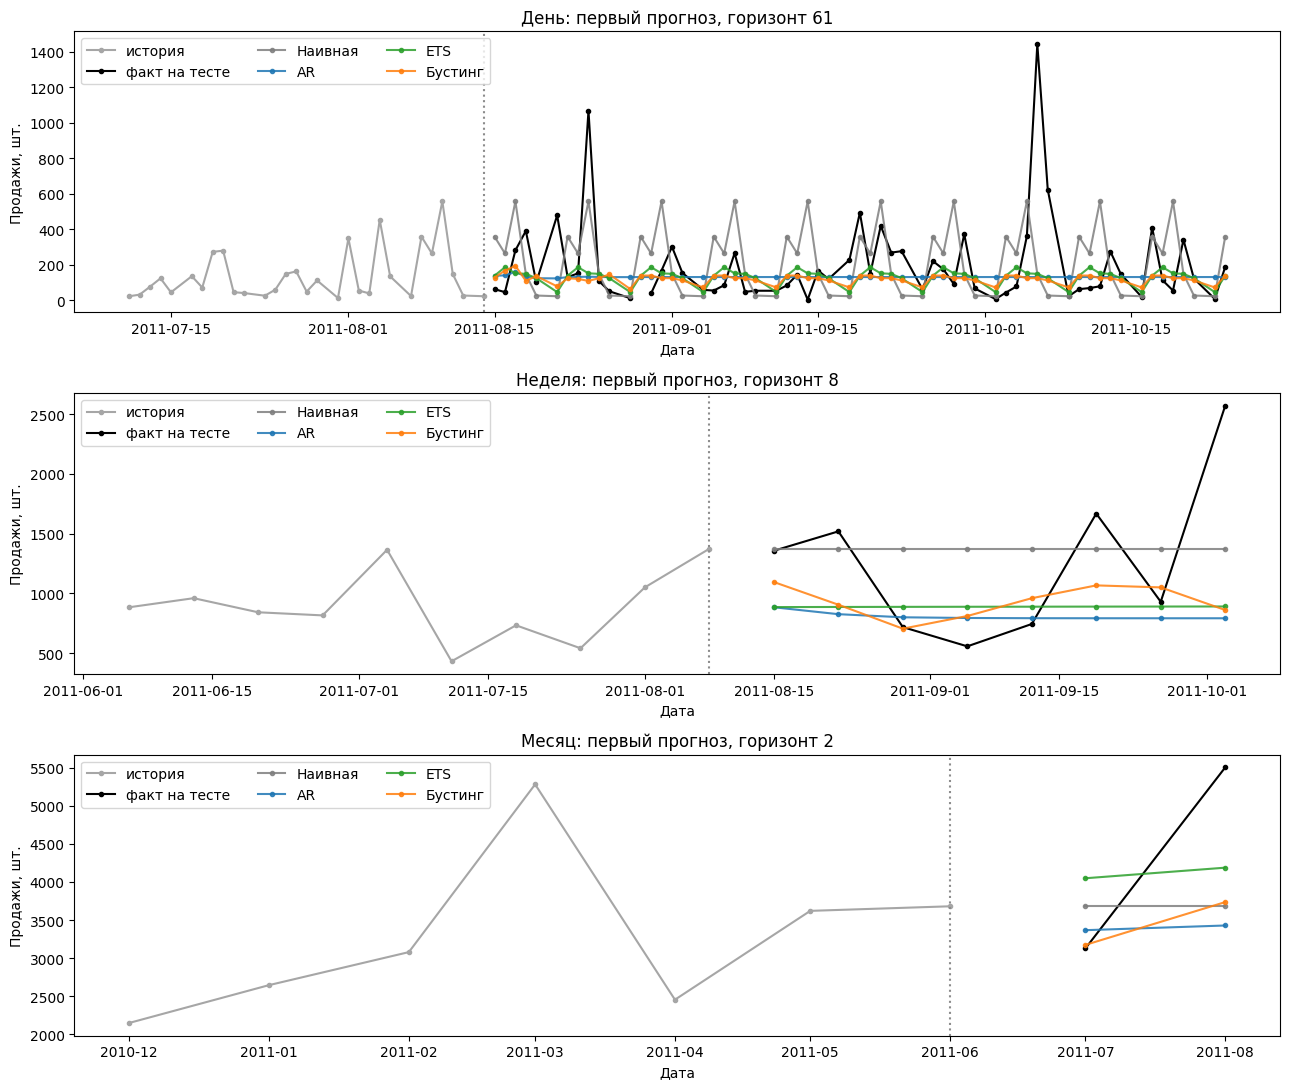

In [9]:
colors = {'Наивная': 'tab:gray', 'AR': 'tab:blue', 'ETS': 'tab:green', 'Бустинг': 'tab:orange'}
fig, axes = plt.subplots(3, 1, figsize=(13, 11))

for (freq, y), ax in zip(series.items(), axes):
    cut = len(y) - test_sizes[freq]
    history_size = {'День': 30, 'Неделя': 10, 'Месяц': 7}[freq]
    train_tail = y.iloc[max(0, cut - history_size):cut]
    ax.plot(train_tail, color='0.65', marker='.', label='история')
    run = predictions.loc[predictions['frequency'].eq(freq) & predictions['last_train_period'].eq(y.index[cut - 1])]
    actual = run.drop_duplicates('date')
    ax.plot(actual['date'], actual['actual'], color='black', marker='.', label='факт на тесте')
    for model, p in run.groupby('model', sort=False):
        ax.plot(p['date'], p['forecast'], color=colors[model], marker='.', alpha=0.85, label=model)

    ax.axvline(train_tail.index[-1], color='0.55', linestyle=':')
    ax.set(title=f'{freq}: первый прогноз, горизонт {max(horizons[freq])}',
           xlabel='Дата', ylabel='Продажи, шт.')
    ax.legend(ncol=3)

fig.tight_layout()
plt.show()

Следующий график сравнивает WAPE для всех горизонтов. По горизонтали показаны шаги соответствующей частоты, по вертикали — ошибка в процентах.

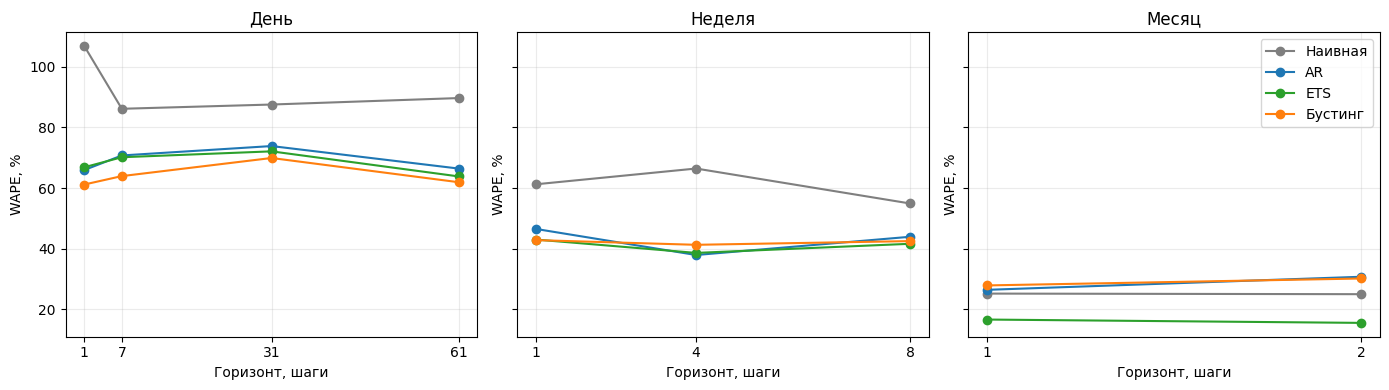

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for (freq, steps), ax in zip(horizons.items(), axes):
    block = scores.loc[scores['frequency'].eq(freq)]
    for model, p in block.groupby('model', sort=False):
        ax.plot(p['horizon'], p['WAPE, %'], marker='o', color=colors[model], label=model)
    ax.set(title=freq, xlabel='Горизонт, шаги', ylabel='WAPE, %', xticks=steps)
    ax.grid(alpha=0.25)

axes[-1].legend()
fig.tight_layout()
plt.show()

## Шаг 6. Выводы

- **День.** Бустинг лучший на всех четырёх горизонтах. WAPE растёт с 61,2% на одном шаге до 69,9% на 31-м, затем падает до 61,9% на 61-м. Пики всё равно плохо ловятся: 6 октября факт 1443 шт., а прогноз бустинга на 31 шаг — 143 шт. В ДЗ №1 в этот день был виден отдельный заказ на 1000 шт.
- **Неделя.** На одном шаге бустинг (42,8%) почти совпал с ETS (43,0%). На четырёх шагах лучшая AR (37,9%), на восьми — ETS (41,6%). На девяти запусках разница в несколько десятых процентного пункта мало о чём говорит.
- **Месяц.** ETS на обоих горизонтах даёт наименьший WAPE (16,6% и 15,5%). При этом MAE растёт с 741 до 795 шт.: на втором горизонте выше общий объём факта, от которого считается WAPE. Месячных точек всего 12, оценка на четырёх запусках чувствительна к отдельным месяцам.

Ошибка с горизонтом растёт не везде: при тех же точках запуска дальний прогноз проверяется на более позднем участке ряда. Дневная ошибка самая высокая, там сильнее влияние отдельных заказов. Если нужен прогноз для планирования запасов этой сумки, я бы начал с недельного ряда и сравнил модели ещё на нескольких месяцах данных.